# Video game completion time prediction Endterm

**Syrym Shadiyarbek and Yerdaulet Akhanov · Direction 42 · Regression**

Can real additional game metadata and the Week 5-8 methods improve main-story duration estimates for a player choosing a game that fits a time budget?

This notebook preserves the midterm cohort, IGDB target values and split. It adds real IGDB and Steam features, controlled feature ablation, tuned ensembles, target-free PCA/clustering and a neural network. Descriptions remain reserved for the Final.

All displayed values come from included source snapshots and executed experiments. The notebook checks their hashes, then displays the saved results by default. Set `RETRAIN=True` below to rerun the supervised and unsupervised experiments offline. Live API recollection is deliberately separate so opening the notebook does not change the benchmark or require secrets.

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), Path.cwd().parent] if (p / 'src' / 'train.py').exists())
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import pandas as pd
pd.set_option('display.max_rows', 100)
from IPython.display import display, Markdown, Image
from common import CLEAN, OUT, MIDTERM, sha256
from train import load_data
from features import input_columns, DISALLOWED_DURATION_TOKENS
df, training, test = load_data()
collection = json.loads((ROOT / 'data/raw/collection_manifest.json').read_text())
quality = json.loads((CLEAN / 'enrichment_report.json').read_text())
print('Project:', ROOT.name)
print('Original cohort:', len(df), 'Training:', len(training), 'Test:', len(test))
print('Collection completion UTC:', collection['completed_at_utc'])
print('Target: IGDB hastily / 3600, frozen 8 October 2026')

Project: endterm
Original cohort: 5229 Training: 4183 Test: 1046
Collection completion UTC: 2026-11-01T21:49:31.274363+00:00
Target: IGDB hastily / 3600, frozen 8 October 2026


## 1 Data provenance and source access

One row is one real game. The original collection used IGDB's `hastily` average seconds to main credits without notable extras. The old raw field is misleadingly named `hltb_main_hours`, but its `time_source` and manifest identify IGDB. We do not merge different target definitions.

New IGDB `/v4/games` responses add themes, gameplay keywords, modes, perspectives, platforms, engines and game type. Public Steam Browse and tag-list endpoints add top user tags, categories and supported platforms/languages. Batched Store `appdetails` supplies explicit USD quotes. Links use explicit Steam app IDs/URLs in IGDB, not fuzzy title matching. Each raw response has a URL or endpoint and UTC timestamp.

The source check snapshots are retained in `data/raw/source_checks`. Steam robots rules do not disallow the routes used. The IGDB website robots request returned 403, so we use its authenticated API rather than scrape the website. Terms and documentation are retained; robots access is not a redistribution license. No individual user reviews, profiles or private-person data were collected. Credentials never enter a project file.

Sources: [IGDB API](https://api-docs.igdb.com/), [Steam API overview](https://partner.steamgames.com/doc/webapi_overview), [Steam API terms](https://steamcommunity.com/dev/apiterms).

In [2]:
display(pd.DataFrame([{
    'original_games': quality['original_rows'],
    'expanded_games': quality['enriched_rows'],
    'new_IGDB_responses': quality['igdb_returned_rows'],
    'successful_Steam_rows': quality['steam_metadata_rows'],
    'observed_USD_prices': quality['usd_price_rows'],
    'observed_Steam_tags': quality['steam_tag_rows'],
    'cross_partition_Steam_overlap_rows': quality['test_rows_with_steam_app_in_training']
}]).T.rename(columns={0:'Measured count'}))
display(df[['game_id','title','main_story_hours','igdb_game_type','igdb_game_modes',
            'igdb_themes','steam_regular_price_usd','steam_tags']].head(6))

,Measured count
original_games,5229
expanded_games,5229
new_IGDB_responses,5229
successful_Steam_rows,3334
observed_USD_prices,2861
observed_Steam_tags,3333
cross_partition_Steam_overlap_rows,23


,game_id,title,main_story_hours,igdb_game_type,igdb_game_modes,igdb_themes,steam_regular_price_usd,steam_tags
0,1,Thief II: The Metal Age,28.0,Main Game,Single player,Action|Fantasy|Stealth,6.99,Stealth|Classic|Steampunk|Atmospheric|First-Pe...
1,100157,Morkredd,4.0,Main Game,Co-operative|Multiplayer|Single player,NaN,19.99,Physics|Puzzle|Local Co-Op|Dark|Atmospheric|Lo...
2,10028,"Batman: Arkham Origins - Cold, Cold Heart",2.0,DLC,Multiplayer|Single player,Action,9.99,Action|Adventure|Open World|Third Person|Singl...
3,10032,Ancestors: The Humankind Odyssey,19.0,Main Game,Single player,Action|Open world|Survival,39.99,Open World Survival Craft|Survival|Open World|...
4,100357,Temtem,100.0,Main Game,Co-operative|Massively Multiplayer Online (MMO...,Action|Fantasy,44.99,Co-op|Multiplayer|Creature Collector|Turn-Base...
5,1004,The Matrix: Path of Neo,9.0,Main Game,Single player,Action|Comedy|Science fiction,NaN,NaN


## 2 Feature dictionary and missing data

The complete field dictionary distinguishes model inputs, provenance and historical fields. Prices are **current US-region USD** quotes, not launch prices. Missing quotes never become zero-price claims. Missing stored data remain missing; numeric medians and indicators used for model computation are learned separately inside each training fold. Targets are never imputed.

The old `price_usd` and `tags_text` columns are retained as historical evidence. The new observed values live in `steam_regular_price_usd`, `steam_current_price_usd`, and `steam_tags`, so the old snapshot is not silently rewritten.

Stored columns: 70 Raw model inputs: 39


,field,stored_type,meaning,model_input,observed_rows
0,game_id,int64,Frozen IGDB game identifier; one game per row.,False,5229
1,steam_appid,float64,Steam ID stored in the October midterm submiss...,False,3343
2,title,str,Game name in the frozen midterm snapshot.,False,5229
3,main_story_hours,float64,Regression target: IGDB hastily seconds / 3600...,False,5229
4,release_year,float64,Release year retained from midterm IGDB first ...,True,5227
5,price_usd,float64,"Historical midterm price field, entirely missi...",False,0
6,primary_genre,str,First genre in the original sorted IGDB genre ...,True,5229
7,genres_text,str,Pipe-separated original IGDB genre categories.,True,5149
8,tags_text,float64,"Historical midterm tag field, entirely empty; ...",False,0
9,primary_developer,str,Original primary studio name; converted to a f...,True,5228


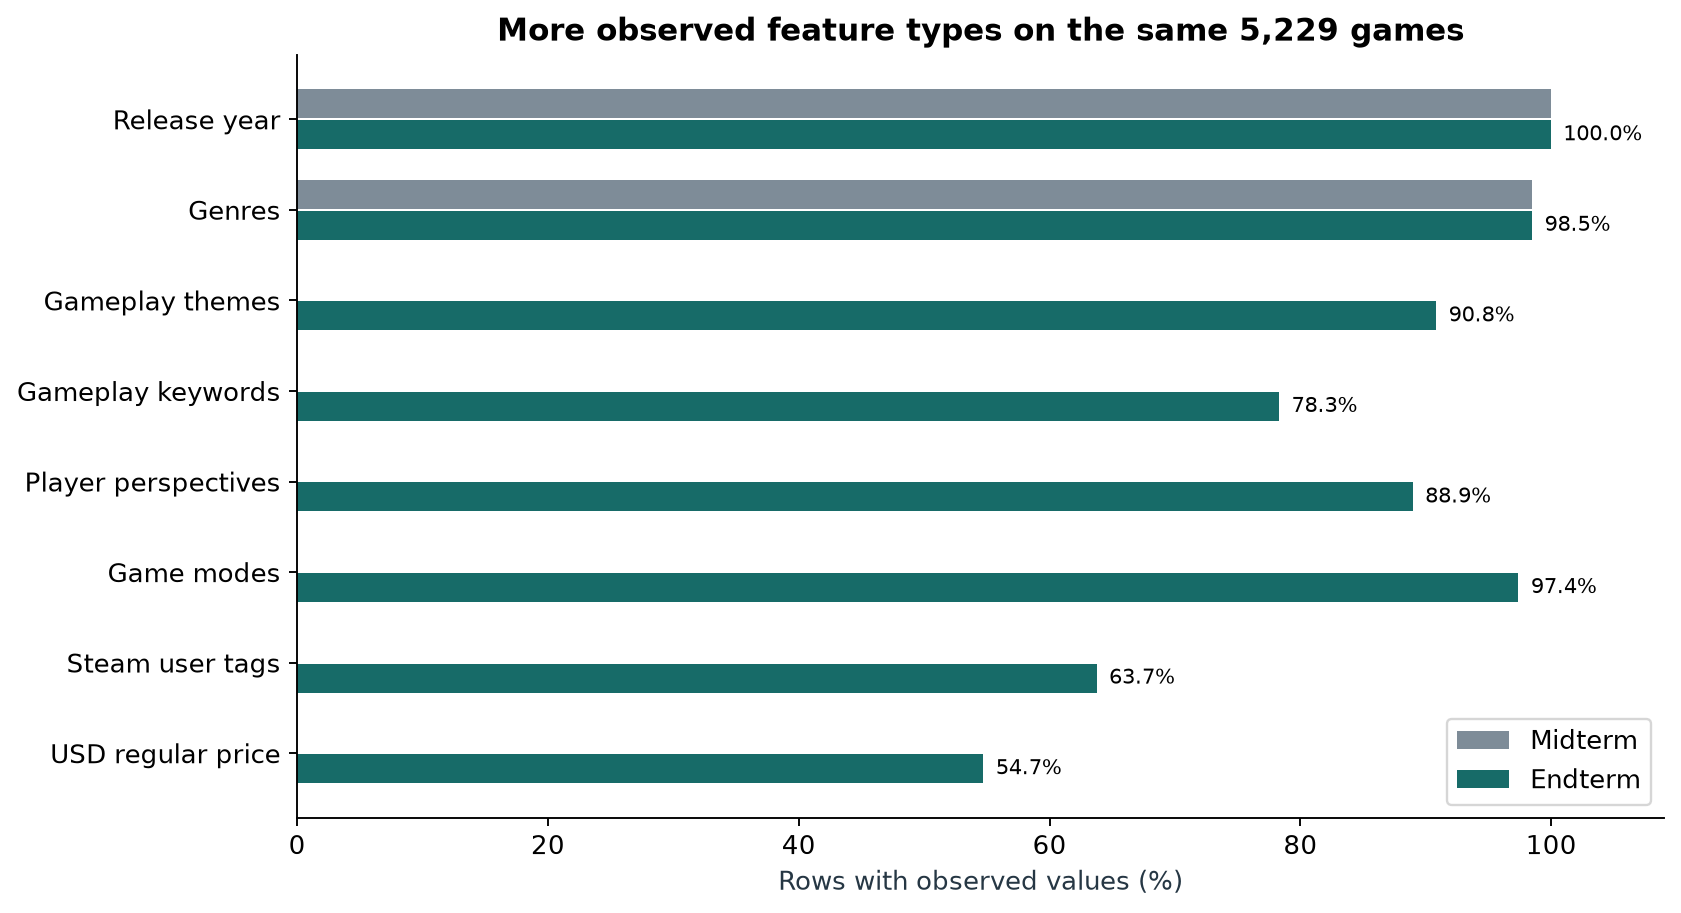

In [3]:
dictionary = pd.read_csv(CLEAN / 'data_dictionary.csv')
print('Stored columns:', len(dictionary), 'Raw model inputs:', len(input_columns('full')))
display(dictionary[['field','stored_type','meaning','model_input','observed_rows']])
display(Image(filename=str(OUT / 'figures/feature_coverage.png'), width=850))

## 3 Cohort and leakage checks

The midterm cleaned 5,273 raw rows to 5,229 games by excluding 34 invalid/incomplete records and removing 10 duplicates. Endterm adds no rows and removes no rows. It left-joins real metadata and preserves every target and split assignment. The held-out test was already published at midterm, so this is an honest stage comparison rather than a fresh independent benchmark.

In [4]:
original = pd.read_csv(MIDTERM / 'data/clean/games_clean.csv', dtype={'game_id':str})
assert original.game_id.tolist() == df.game_id.tolist()
np.testing.assert_array_equal(original.main_story_hours, df.main_story_hours)
assert sha256(CLEAN / 'fixed_split.csv') == sha256(MIDTERM / 'data/clean/fixed_split.csv')
assert df.main_story_hours.notna().all() and df.main_story_hours.gt(0).all()
forbidden = {'main_story_hours','description','title','game_id','hastily','normally','completely','time_submissions'}
assert not set(input_columns('full')) & forbidden
print('Exact game cohort, target values and split preserved.')
print('Excluded duration tokens:', sorted(DISALLOWED_DURATION_TOKENS))
print('All preprocessing is fitted within training folds; raw missingness is retained.')

Exact game cohort, target values and split preserved.
Excluded duration tokens: ['long', 'long game', 'long games', 'long playtime', 'short', 'short game', 'short games', 'short playtime']
All preprocessing is fitted within training folds; raw missingness is retained.


### Cleaning evidence and model settings

The audit reconstructs each original cleaning decision and checks stored prices and tags against the raw Steam responses. The audit adds no games and changes no labels. Model settings below explain why each candidate was included.

The inherited target filter accepts finite 0.1–1,000-hour labels. All 28 excluded durations are below six minutes; they are not proven wrong. Five descriptions fail the eight-word minimum and one title fails the two-character minimum. Ten normalized-title/year duplicates are removed. These rules support text readiness and deduplication, but can exclude real short games or different editions. They are preserved for stage comparability; the row-level audit below records their outcomes.


In [5]:
from audit_data import run as audit_sources
audit_sources()
display(pd.read_csv(CLEAN / 'cleaning_steps.csv'))
display(pd.read_csv(CLEAN / 'cleaning_audit.csv').query("not kept")[['game_id','title','reason']].head(12))
display(pd.read_csv(OUT / 'model_specifications.csv'))


Cleaning lineage, observed prices and tags verified.


,step,rows_before,removed,rows_after
0,Raw snapshot,5273,0,5273
1,Invalid target / insufficient text / unusable ...,5273,34,5239
2,Duplicate normalized title and release year,5239,10,5229
3,Duplicate game ID,5229,0,5229


,game_id,title,reason
1187,10208,Blockout,invalid_target
1541,19325,Neon Space,invalid_target
1963,30075,Santa's Big Adventures,invalid_target
2325,66396,Space Station 13,invalid_target
2451,81094,Banyu Lintar Angin: Little Storm,invalid_target
2681,110468,September 1999,invalid_target
2763,114781,Data,invalid_target
2837,117996,Absolutely: A True Crime Story,invalid_target
2888,120272,Inventor,invalid_target
3041,128651,Hungry Knight!,invalid_target


,model,feature_set,parameters,selected_search_parameters,reason
0,Median baseline,midterm,Training-label median,{},Minimum-complexity reference for absolute error.
1,Ridge original features,midterm,alpha=20; solver=lsqr; log1p target,{},Regularized linear reference; identical settin...
2,Ridge expanded IGDB,igdb,alpha=20; solver=lsqr; log1p target,{},Regularized linear reference; identical settin...
3,Ridge IGDB + Steam,full,alpha=20; solver=lsqr; log1p target,{},Regularized linear reference; identical settin...
4,ExtraTrees original features,midterm,200 trees; min_samples_leaf=3; max_features=0....,{},Randomized tree ensemble; identical settings i...
5,ExtraTrees expanded IGDB,igdb,200 trees; min_samples_leaf=3; max_features=0....,{},Randomized tree ensemble; identical settings i...
6,ExtraTrees IGDB + Steam,full,200 trees; min_samples_leaf=3; max_features=0....,{},Randomized tree ensemble; identical settings i...
7,Random forest,full,250 trees; min_samples_leaf=3; max_features=0....,{},Averages bootstrap-trained trees to reduce sin...
8,Tuned gradient boosting,full,250 iterations; learning_rate=0.07; absolute_e...,"{""model__l2_regularization"": 10, ""model__max_l...",Fits the primary hour-scale absolute-error obj...
9,Tuned neural network,full,"Hidden layers (32,) or (64,32); alpha=0.01 or ...","{""regressor__model__alpha"": 0.1, ""regressor__m...",Tests nonlinear combinations of structured inp...


## 4 Exploration on training rows

The training median is 5 hours, the 95th percentile 40 hours and the 99th percentile 100 hours. This tail motivates MAE as the main metric and log-target experiments, while RMSE/R2 keep large errors visible.

The recorded RPG genre has median 14.25 hours (246 training games), compared with 3 hours for Indie (374 games). Broad genre differences support retaining all genre categories and adding gameplay descriptors.

Among 2,305 training games with observed prices, price/duration Spearman correlation is 0.618. This supports testing prices jointly with other metadata; it is not a causal effect and applies only to the observed-price subset.


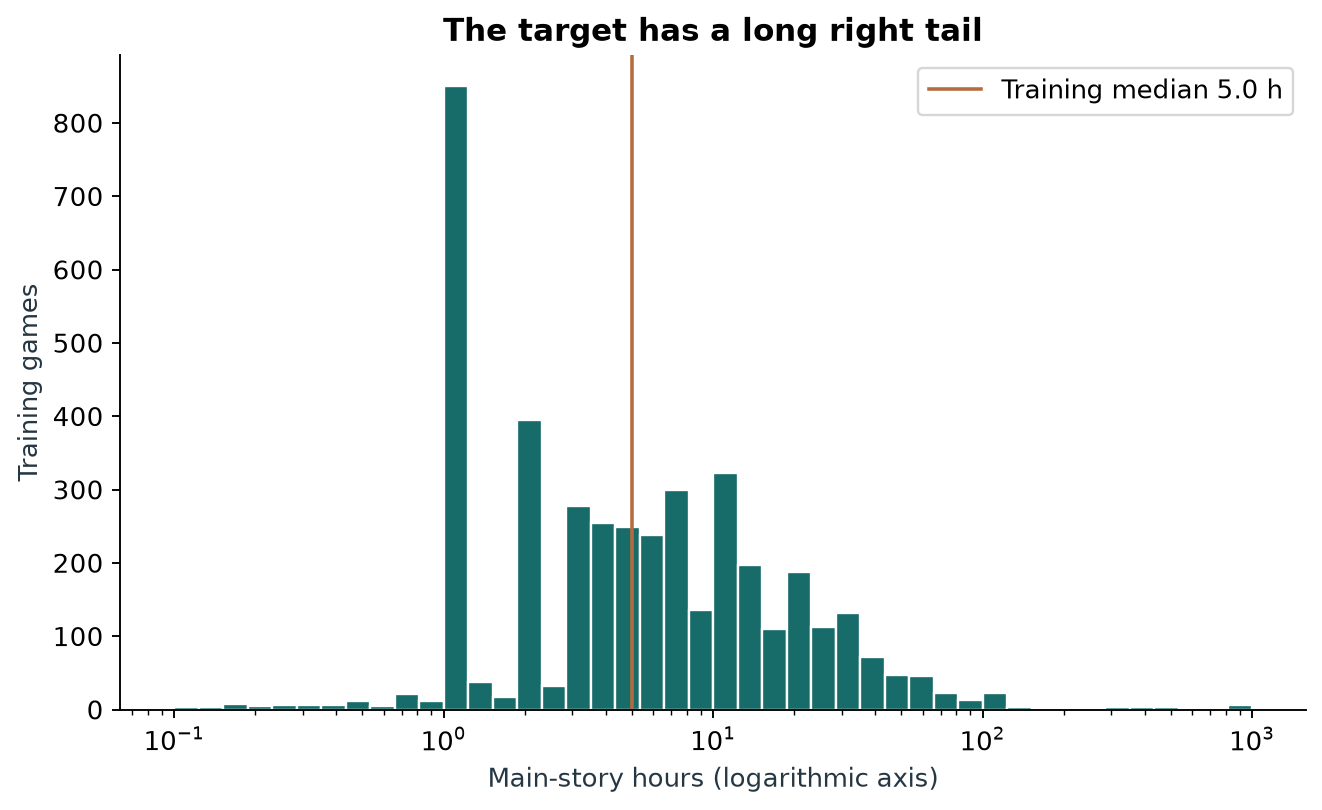

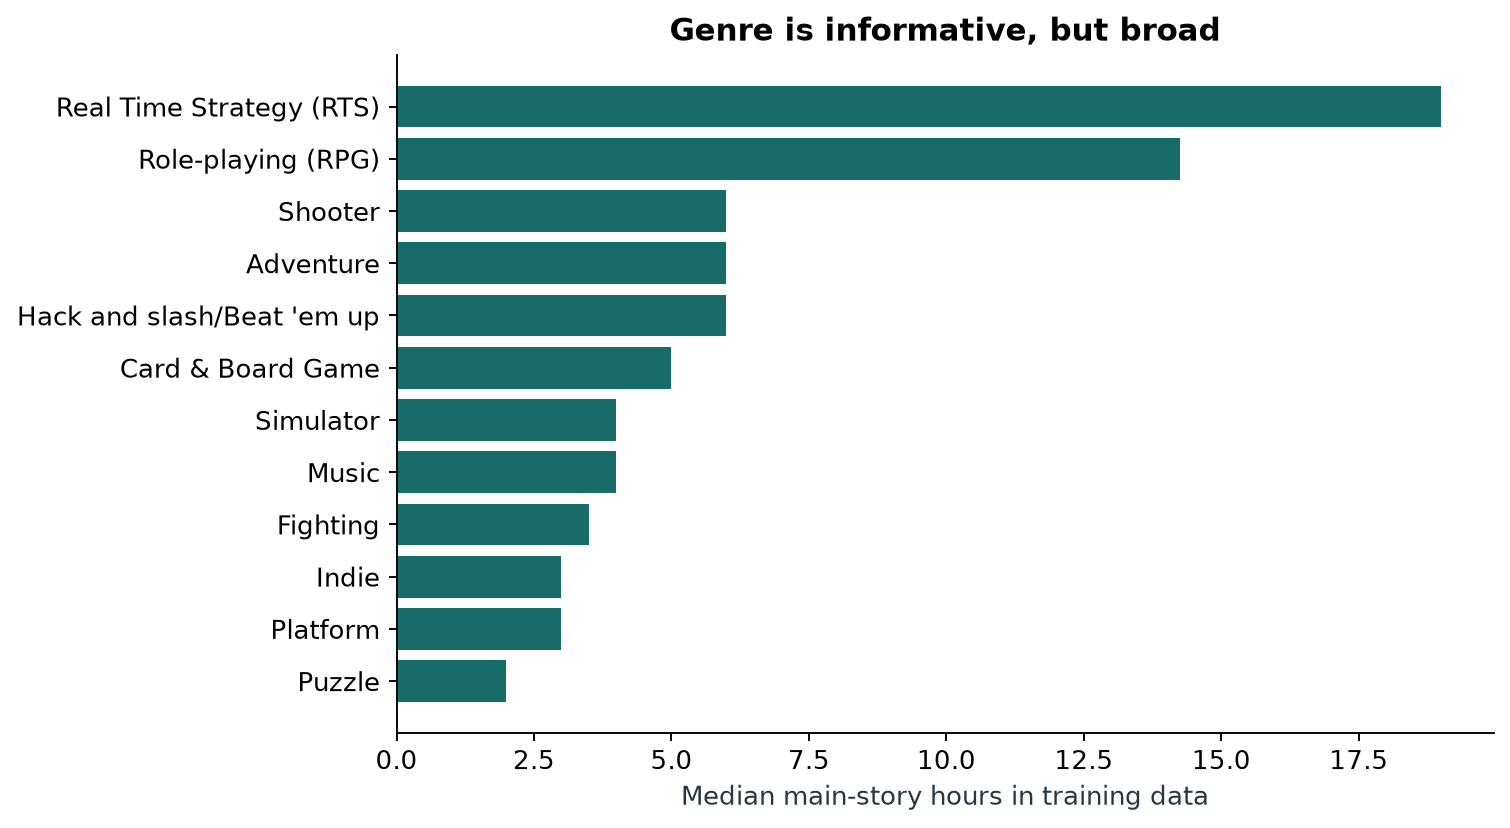

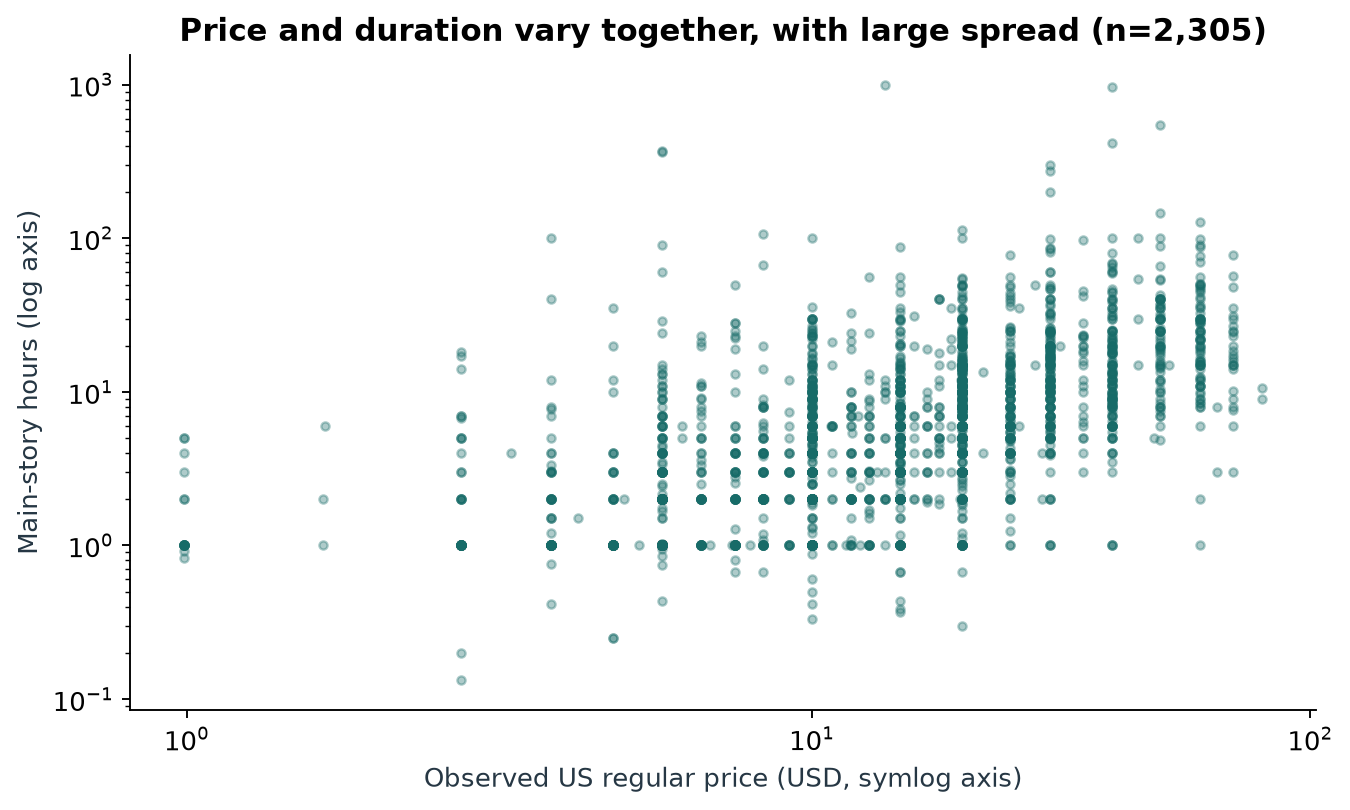

,Training hours
0.25,2.0
0.50,5.0
0.75,12.0
0.95,40.0
0.99,100.0
1.00,1000.0


In [6]:
for filename in ['target_distribution.png','genre_duration.png','price_duration.png']:
    display(Image(filename=str(OUT / 'figures' / filename), width=760))
display(training.main_story_hours.quantile([.25,.5,.75,.95,.99,1]).rename('Training hours').to_frame())

## 5 Experimental design

The fixed 4,183/1,046 train/test split uses seed 42. We compare models using three shuffled folds inside training. The median predictor is the baseline. Ordinary linear regression, Ridge, a depth-limited decision tree and scaled KNN provide the Week 3-4 references on the original feature family. The full comparison contains 13 models; their reasons and parameters are recorded in model_specifications.csv. Ridge and ExtraTrees use the same settings across original features, added IGDB features, and IGDB plus Steam to isolate feature-set effects. The expanded candidate with the lowest mean training CV MAE is selected before new test evaluation.

The pipeline learns studio catalog tiers, numeric medians/indicators/scales, categorical encodings and multi-hot vocabularies in training folds only. A developer tier is sample frequency, not company size. Explicit duration tags, IDs, names, descriptions, URLs and all other time-to-beat fields are excluded. Ridge/forests fit log1p hours, neural targets also receive training-fitted standardization, and absolute-error gradient boosting fits raw hours. All public errors use original hours.

The boosting grid contains eight configurations; the neural grid contains four. Tuning CV is not nested CV and its score is a selection estimate. CV spread below is fold standard deviation, not a 95% interval.

In [7]:
RETRAIN = False
if RETRAIN:
    from train import run as train_models
    from cluster import run as cluster_models
    from plots import run as plot_results
    train_models()
    cluster_models()
    plot_results()
manifest = json.loads((OUT / 'experiment_manifest.json').read_text())
assert manifest['dataset_sha256'] == sha256(CLEAN / 'games_enriched.csv')
assert manifest['split_sha256'] == sha256(CLEAN / 'fixed_split.csv')
selection = json.loads((OUT / 'model_selection.json').read_text())
print('Verified experiment completed UTC:', manifest['completed_at_utc'])
print('Selected before test scoring:', selection['winner'])
print('Encoded feature count:', manifest['encoded_features'])
comparison = pd.read_csv(OUT / 'model_comparison.csv')
display(comparison[['model','feature_set','train_cv_MAE_hours','train_cv_MAE_std_hours',
                    'test_MAE_hours','test_RMSE_hours','test_R2','test_MedAE_hours','test_sMAPE_percent']].round(3))

Verified experiment completed UTC: 2026-11-01T22:01:01.431848+00:00
Selected before test scoring: Tuned gradient boosting
Encoded feature count: 473


,model,feature_set,train_cv_MAE_hours,train_cv_MAE_std_hours,test_MAE_hours,test_RMSE_hours,test_R2,test_MedAE_hours,test_sMAPE_percent
0,Median baseline,midterm,11.075,0.716,13.013,52.166,-0.041,4.000,87.597
1,Ridge original features,midterm,10.074,0.680,11.813,51.426,-0.012,3.199,74.779
2,Ridge expanded IGDB,igdb,9.254,0.656,10.688,50.362,0.029,2.548,63.535
3,Ridge IGDB + Steam,full,9.157,0.680,10.705,50.491,0.024,2.422,61.877
4,ExtraTrees original features,midterm,10.014,0.665,11.702,51.121,-0.000,3.390,71.860
5,ExtraTrees expanded IGDB,igdb,9.222,0.695,10.822,50.529,0.023,2.498,61.360
6,ExtraTrees IGDB + Steam,full,8.772,0.743,10.489,50.542,0.022,2.366,57.533
7,Random forest,full,8.670,0.663,10.333,50.509,0.024,2.289,56.795
8,Tuned gradient boosting,full,8.639,0.602,10.260,50.520,0.023,2.387,56.568
9,Tuned neural network,full,9.016,0.637,10.412,50.182,0.036,2.291,57.695


### gradient boosting

,params,mean_test_score,std_test_score,rank_test_score
6,"{'model__l2_regularization': 10, 'model__max_l...",-8.639172,0.491153,1
2,"{'model__l2_regularization': 1, 'model__max_le...",-8.648773,0.492042,2
3,"{'model__l2_regularization': 1, 'model__max_le...",-8.692399,0.496499,3
7,"{'model__l2_regularization': 10, 'model__max_l...",-8.704424,0.518635,4
4,"{'model__l2_regularization': 10, 'model__max_l...",-8.705222,0.493969,5
0,"{'model__l2_regularization': 1, 'model__max_le...",-8.711614,0.510877,6
1,"{'model__l2_regularization': 1, 'model__max_le...",-8.729049,0.495442,7
5,"{'model__l2_regularization': 10, 'model__max_l...",-8.751722,0.486329,8


### neural network

,params,mean_test_score,std_test_score,rank_test_score
3,"{'regressor__model__alpha': 0.1, 'regressor__m...",-9.015778,0.520152,1
1,"{'regressor__model__alpha': 0.01, 'regressor__...",-9.035073,0.518725,2
2,"{'regressor__model__alpha': 0.1, 'regressor__m...",-9.155694,0.496795,3
0,"{'regressor__model__alpha': 0.01, 'regressor__...",-9.168826,0.502015,4


Search scores are negative MAE, so a less negative value is better.


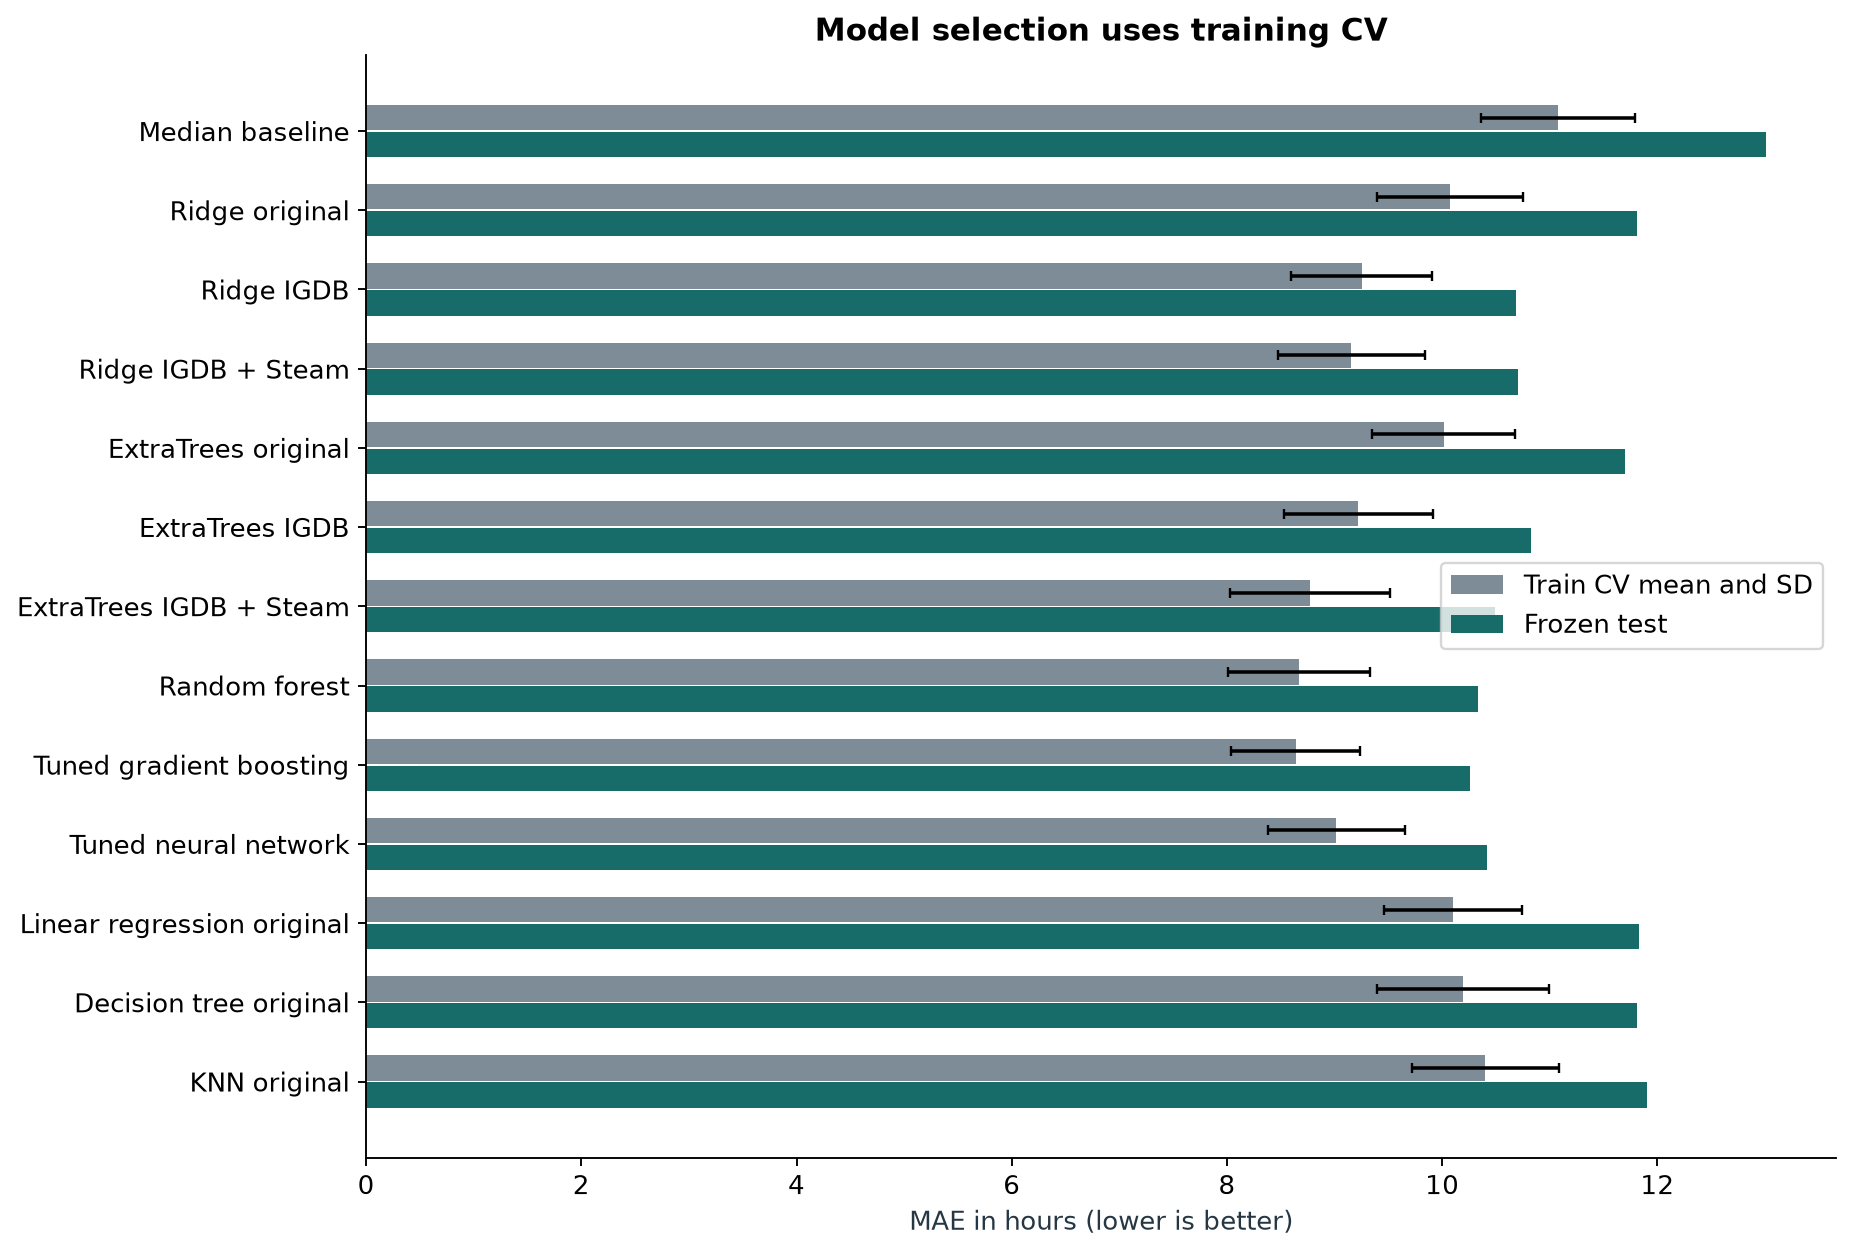

In [8]:
for filename in ['gradient_boosting.csv','neural_network.csv']:
    search = pd.read_csv(OUT / 'search' / filename)
    display(Markdown('### ' + filename.replace('_',' ').replace('.csv','')))
    display(search[['params','mean_test_score','std_test_score','rank_test_score']].sort_values('rank_test_score'))
print('Search scores are negative MAE, so a less negative value is better.')
display(Image(filename=str(OUT / 'figures/model_comparison.png'), width=900))

## 6 Controlled feature ablations and paired uncertainty

The same Ridge settings and the same ExtraTrees settings are each tested across the three feature sets on identical rows. This separates adding feature types from changing estimator complexity. A feature may be real and useful in principle while adding little after correlated features are already included.

Paired bootstrap intervals resample 1,046 test games 5,000 times. They quantify conditional uncertainty in absolute-error differences for these fitted models and this cohort. They are not causal price/tag effects, do not include all training uncertainty, and do not repair the fact that the test was previously observed at midterm.

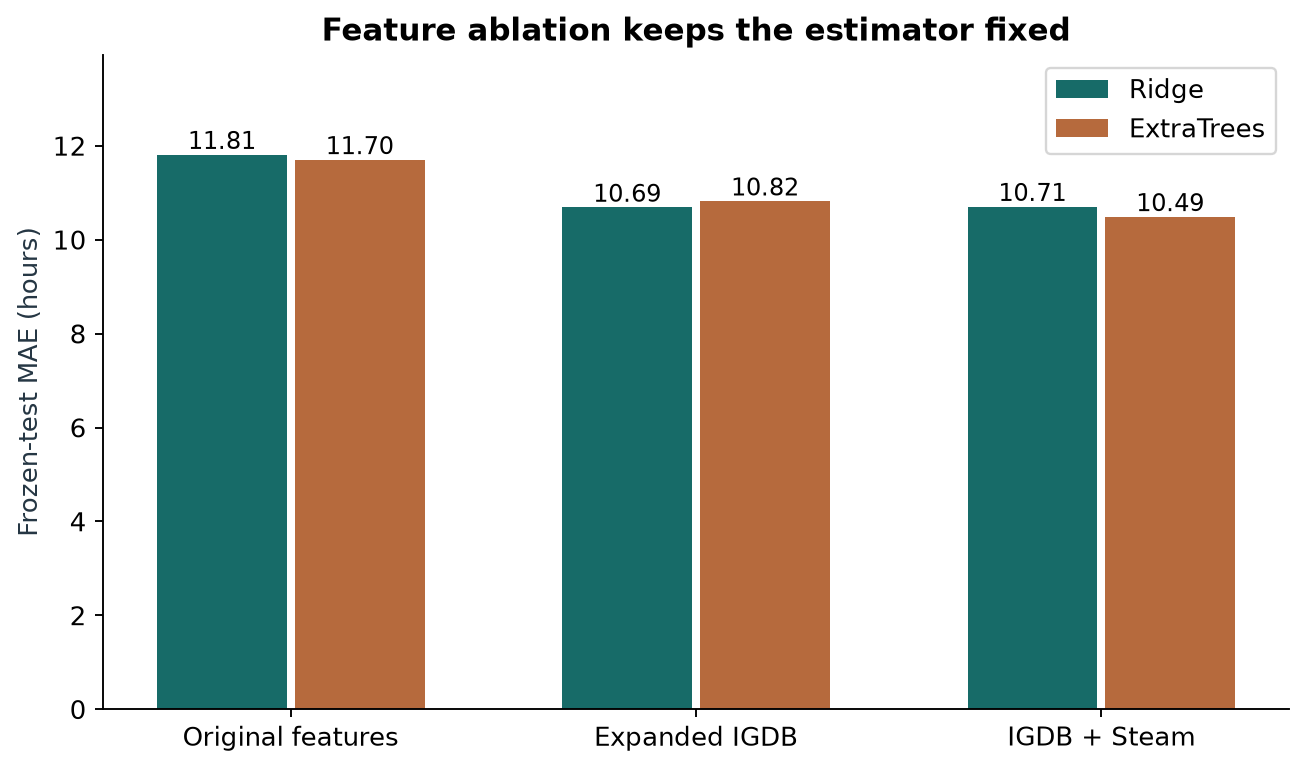

,comparison,MAE reduction hours,lower 95%,upper 95%
0,selected_vs_median,2.753,2.394,3.116
1,selected_vs_retrained_original_ridge,1.553,1.283,1.808
2,ridge_igdb_gain,1.125,0.877,1.378
3,ridge_steam_gain,-0.018,-0.224,0.186
4,extratrees_igdb_gain,0.880,0.546,1.202
5,extratrees_steam_gain,0.333,0.103,0.565
6,selected_vs_submitted_midterm_ridge,1.556,1.285,1.811


Positive reduction favors the new model/feature group. An interval crossing zero means an uncertain gain.


In [9]:
display(Image(filename=str(OUT / 'figures/feature_ablation.png'), width=800))
paired = json.loads((OUT / 'paired_bootstrap.json').read_text())
paired_table = pd.DataFrame([{'comparison': name,
    'MAE reduction hours': value['MAE_reduction_hours'],
    'lower 95%': value['lower_95_hours'], 'upper 95%': value['upper_95_hours']}
    for name,value in paired.items()])
display(paired_table.round(3))
print('Positive reduction favors the new model/feature group. An interval crossing zero means an uncertain gain.')

## 7 Errors, difficult labels and sensitivity

All original test games remain in the main score. We inspect errors by actual duration, genre and concrete game. The longest/open-ended games have questionable fit with a main-story concept, but a large error alone is not evidence that a label is invalid. The label audit records source links instead of inventing corrected durations.

Some editions or entries share a Steam app ID across partitions. The package reports that overlap, evaluates the subset without it, and runs Steam-ID-grouped CV on training rows. Single-player and coverage subsets are descriptive checks, not substitutes for the full score.

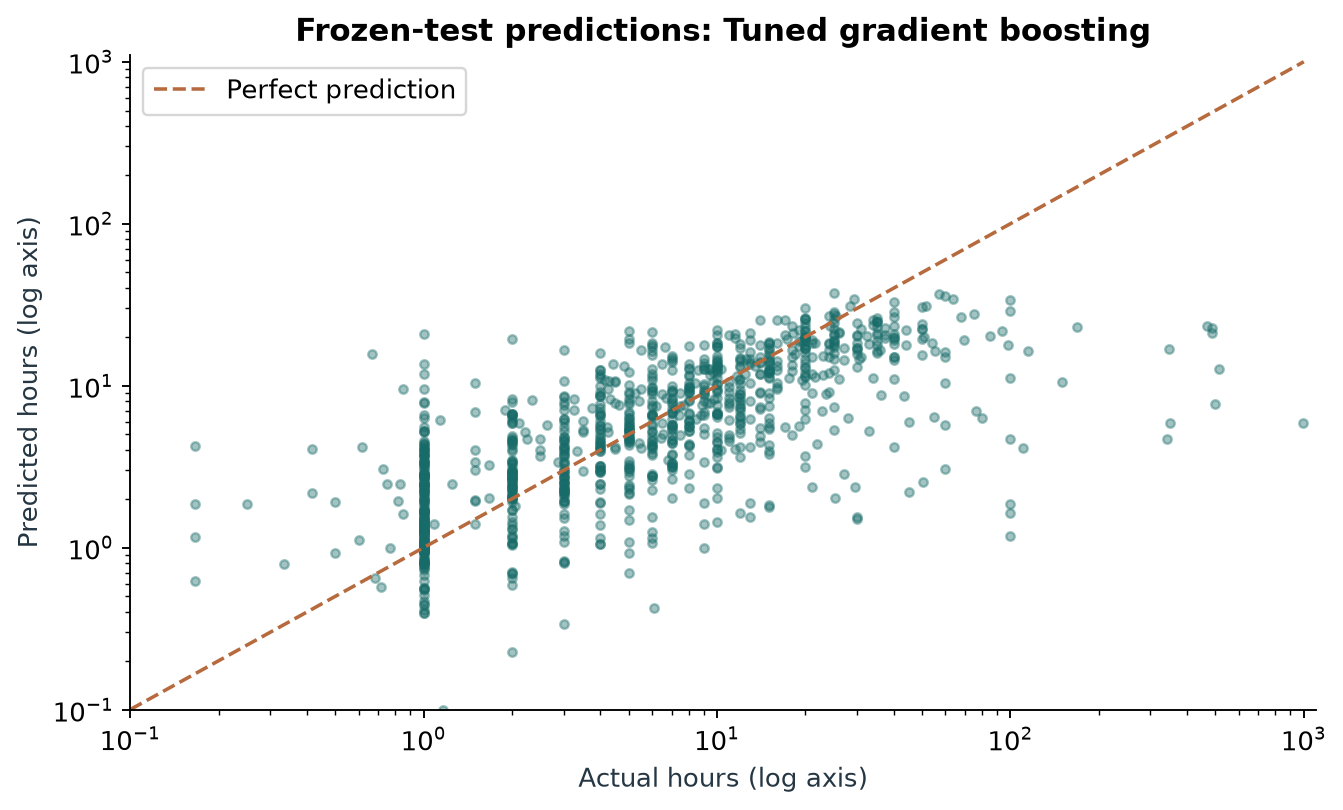

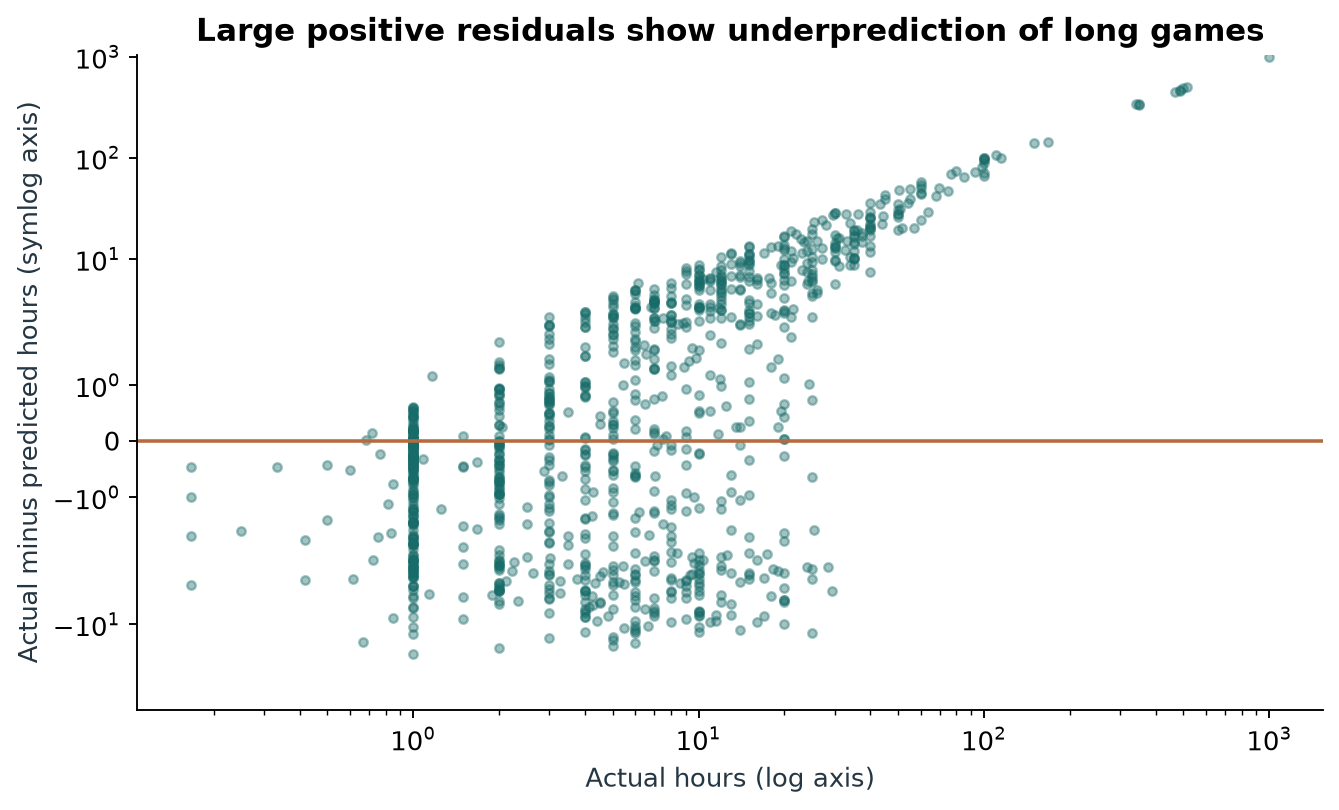

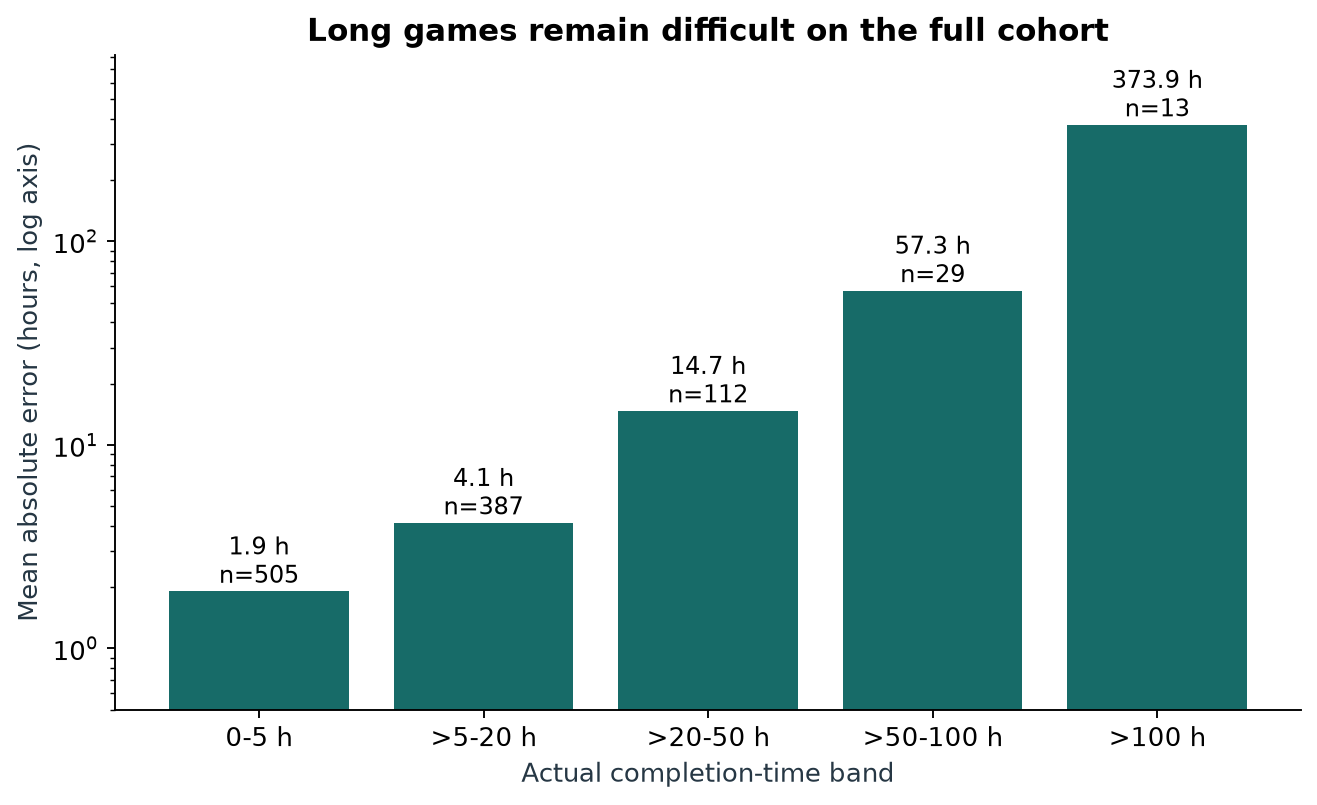

,game_id,title,actual_hours,predicted_hours,absolute_error
0,143228,Gorilla Tag,997.500,5.852,991.648
1,134710,Grand Theft Auto Online,513.000,12.688,500.312
2,7360,Rainbow Six Siege,500.000,7.725,492.275
3,79824,Old School RuneScape,486.500,21.209,465.291
4,373557,HDOS,486.000,22.552,463.448
5,119277,Genshin Impact,468.492,23.303,445.188
6,332780,R.E.P.O.,350.000,5.856,344.144
7,55945,Brawl Stars,342.000,4.712,337.288
8,114009,Dragon Ball Z: Kakarot,348.333,16.815,331.519
9,19012,Riders of Icarus,168.000,23.041,144.959


,primary_genre,count,mean,median
0,Arcade,45,26.894,1.475
1,Shooter,52,12.930,1.713
2,Indie,70,12.666,2.425
3,Hack and slash/Beat 'em up,29,9.639,3.736
4,Adventure,638,9.443,2.429
5,Role-playing (RPG),52,7.652,5.475
6,Unknown,21,7.176,1.914
7,Platform,23,6.749,1.839
8,Racing,13,6.626,2.561
9,Simulator,20,6.575,2.811


,subset,rows,test_MAE_hours,test_RMSE_hours,test_R2,test_MedAE_hours,test_sMAPE_percent
0,All original test games,1046,10.260,50.520,0.023,2.387,56.568
1,No Steam app overlap with training,1023,9.514,47.557,0.028,2.362,56.680
2,IGDB lists single-player,1006,8.098,33.340,0.059,2.387,55.531
3,Steam metadata available,657,9.583,52.370,0.017,2.378,52.802
4,Steam metadata unavailable,389,11.403,47.232,0.034,2.433,62.928


Steam-ID-grouped training CV MAE: 8.661 +/- 0.661 h


In [10]:
for filename in ['predictions.png','residuals.png','error_by_duration.png']:
    display(Image(filename=str(OUT / 'figures' / filename), width=760))
display(pd.read_csv(OUT / 'largest_errors.csv').head(10).round(3))
display(pd.read_csv(OUT / 'error_by_genre.csv').round(3))
display(pd.read_csv(OUT / 'sensitivity_subsets.csv').round(3))
print('Steam-ID-grouped training CV MAE:', round(manifest['grouped_cv_MAE_mean_hours'],3),
      '+/-', round(manifest['grouped_cv_MAE_std_hours'],3), 'h')

## 8 Validation feature importance

We fit the selected configuration on one training fold and permute raw fields in its validation fold. This avoids using test outcomes to rank features. Correlated features can substitute for one another, so permutation importance is not a causal effect and does not measure all joint contributions.

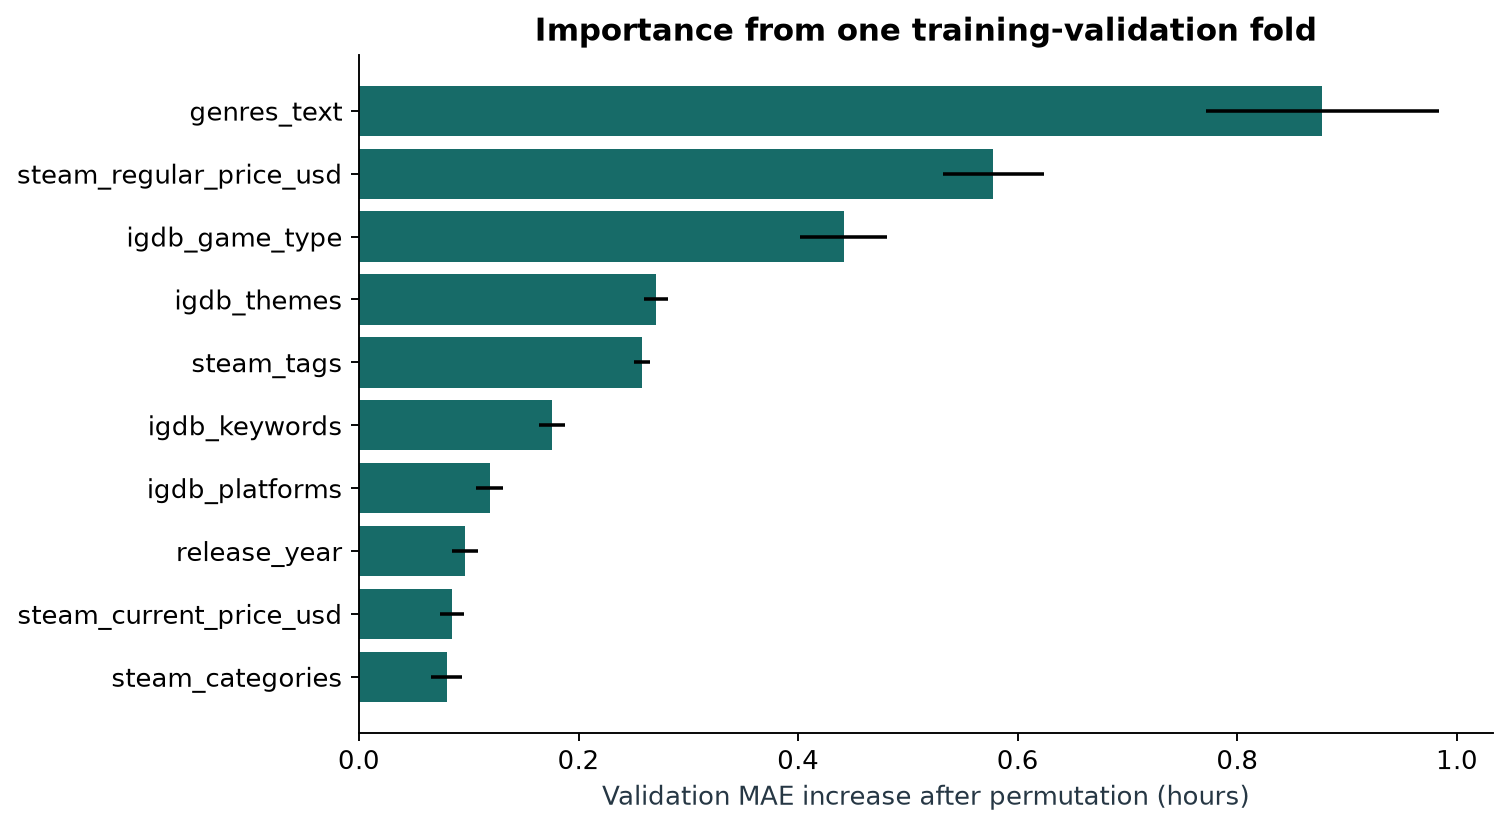

,feature,validation_MAE_increase_hours,std_hours
0,genres_text,0.877,0.106
1,steam_regular_price_usd,0.578,0.046
2,igdb_game_type,0.441,0.040
3,igdb_themes,0.271,0.011
4,steam_tags,0.258,0.007
5,igdb_keywords,0.176,0.012
6,igdb_platforms,0.119,0.012
7,release_year,0.097,0.012
8,steam_current_price_usd,0.085,0.011
9,steam_categories,0.080,0.014


In [11]:
display(Image(filename=str(OUT / 'figures/permutation_importance.png'), width=850))
display(pd.read_csv(OUT / 'permutation_importance.csv').head(12).round(3))

## 9 Neural network

The feed-forward MLP compares a 32-unit hidden layer with a 64/32-unit network, each with two L2 penalties. It uses ReLU, Adam and early stopping with an internal 15% training holdback. The preprocessing and target transformation are fitted within each outer training fold. Learning curves are in standardized log-target units, not error in hours. The network need not win to provide a valid experiment.

,Measured configuration
hidden_layer_sizes,"[64, 32]"
alpha,0.1
iterations,30
max_iter,350
early_stopping,True
validation_fraction,0.15
target_transform,log1p then train-fitted StandardScaler; invers...


,model,train_cv_MAE_hours,train_cv_MAE_std_hours,test_MAE_hours,test_R2
9,Tuned neural network,9.016,0.637,10.412,0.036


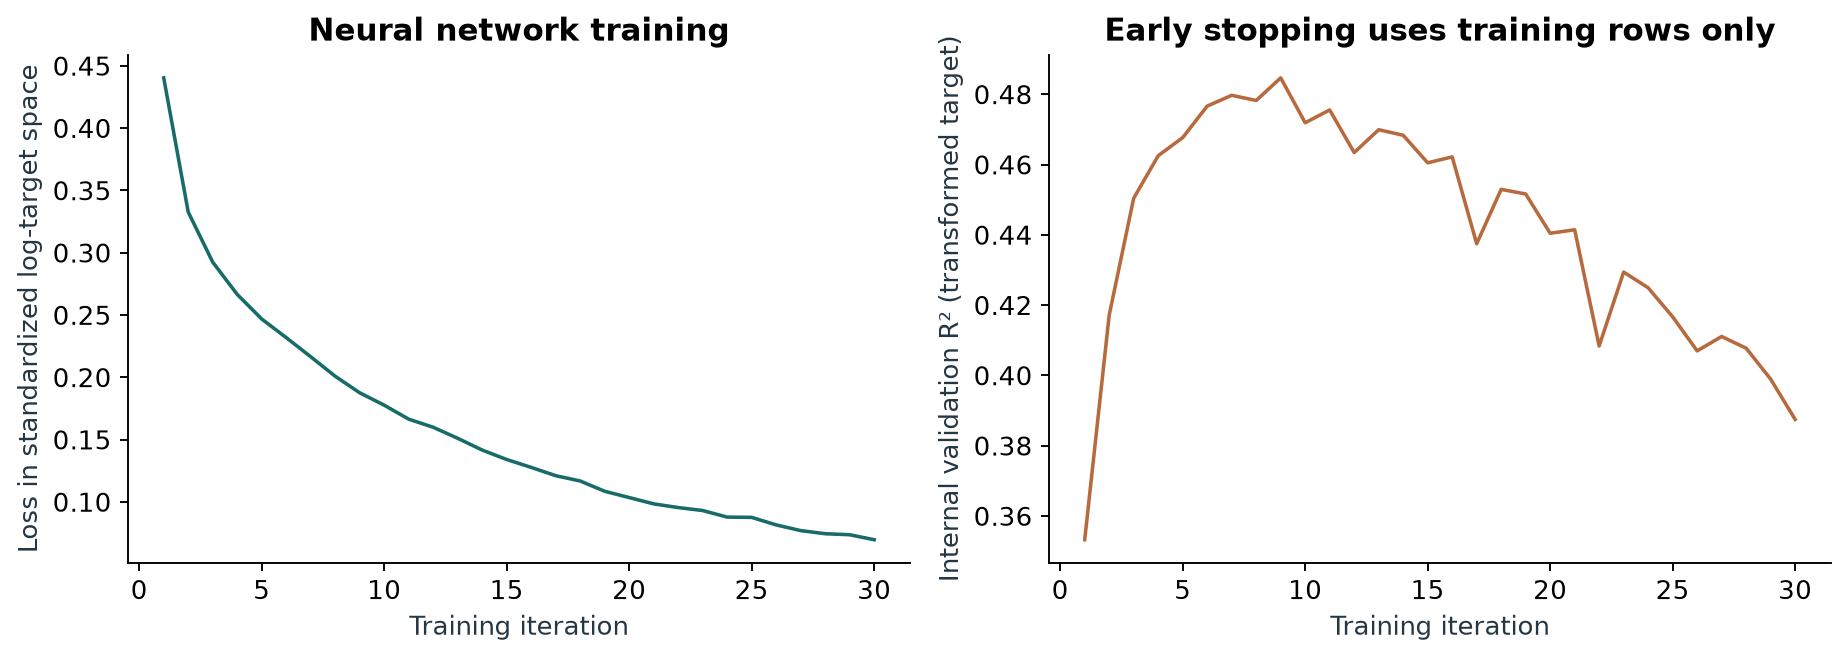

In [12]:
neural = json.loads((OUT / 'neural_network_diagnostics.json').read_text())
display(pd.DataFrame([{key:neural[key] for key in ['hidden_layer_sizes','alpha','iterations','max_iter',
    'early_stopping','validation_fraction','target_transform']}]).T.rename(columns={0:'Measured configuration'}))
display(comparison.loc[comparison.model.eq('Tuned neural network'),
    ['model','train_cv_MAE_hours','train_cv_MAE_std_hours','test_MAE_hours','test_R2']].round(3))
display(Image(filename=str(OUT / 'figures/neural_learning.png'), width=900))

## 10 PCA and clustering

PCA and KMeans fit training predictors only, never duration labels. The initial full-feature diagnostic separated games mainly by Steam coverage and is retained in `outputs/coverage_diagnostic/`. The primary analysis uses multi-hot IGDB genres, themes, keywords, modes and perspectives, excluding Steam fields, prices, numeric counts and explicit missingness flags. Each row is L2-normalized before PCA so the number of source annotations cannot dominate distances. This design decision uses training metadata, not test outcomes.

PCA retains at least 85% of feature variance. KMeans compares k=2..6 using sampled training silhouette and checks stability with another seed. Duration summaries are added after fitting. The first two components are only a projection. Low silhouette indicates weak separation. Clusters are descriptive metadata patterns, not validated game categories.

,0
fit_rows,4183
pca_input_features,157
pca_components,65
retained_variance,0.851187
pc1_pc2_variance,0.151771
selected_k,6
selection,Highest sampled training silhouette over k=2.....
selected_silhouette,0.078254
adjusted_rand_index_second_seed,0.969877
target_used_for_fit_or_selection,False


,k,training_silhouette,inertia,smallest_cluster_rows
0,2,0.0753,2327.0178,1766
1,3,0.0687,2208.3915,1063
2,4,0.0709,2133.9369,720
3,5,0.0752,2066.1870,650
4,6,0.0783,2002.3321,561


,cluster,training_rows,median_duration_hours_for_description_only,steam_coverage_percent,single_player_listed_percent,median_release_year,median_observed_keyword_count,median_observed_theme_count,top_genres,top_igdb_game_modes,top_igdb_themes,top_steam_tags
0,0,1007,2.0,80.635551,99.696356,2021.0,4.0,2.0,"Adventure, Indie, Simulator","Single player, Multiplayer, Co-operative, Spli...","Horror, Mystery, Action, Comedy","Singleplayer, Adventure, Indie, Atmospheric"
1,1,566,3.0,54.063604,99.286988,2016.0,6.0,2.0,"Adventure, Arcade, Fighting","Single player, Multiplayer, Co-operative, Spli...","Action, Fantasy, Science fiction, Comedy","Action, Singleplayer, 2D, Indie"
2,2,561,8.0,55.080214,97.233202,2010.0,45.5,3.0,"Adventure, Shooter, Role-playing (RPG)","Single player, Multiplayer, Co-operative, Spli...","Action, Science fiction, Fantasy, Open world","Singleplayer, Action, Adventure, Atmospheric"
3,3,666,7.5,64.114114,97.553517,2019.0,5.0,2.0,"Adventure, Indie, Role-playing (RPG)","Single player, Multiplayer, Co-operative, Spli...","Fantasy, Action, Comedy, Science fiction","Singleplayer, Indie, RPG, Adventure"
4,4,779,10.0,53.530167,96.068152,2018.0,4.0,2.0,"Adventure, Role-playing (RPG), Hack and slash/...","Single player, Multiplayer, Co-operative, Mass...","Action, Fantasy, Open world, Science fiction","Action, Adventure, Singleplayer, Third Person"
5,5,604,5.0,67.218543,92.127303,2018.5,6.0,2.0,"Adventure, Shooter, Indie","Single player, Multiplayer, Co-operative, Spli...","Action, Science fiction, Horror, Survival","Action, Singleplayer, Multiplayer, Co-op"


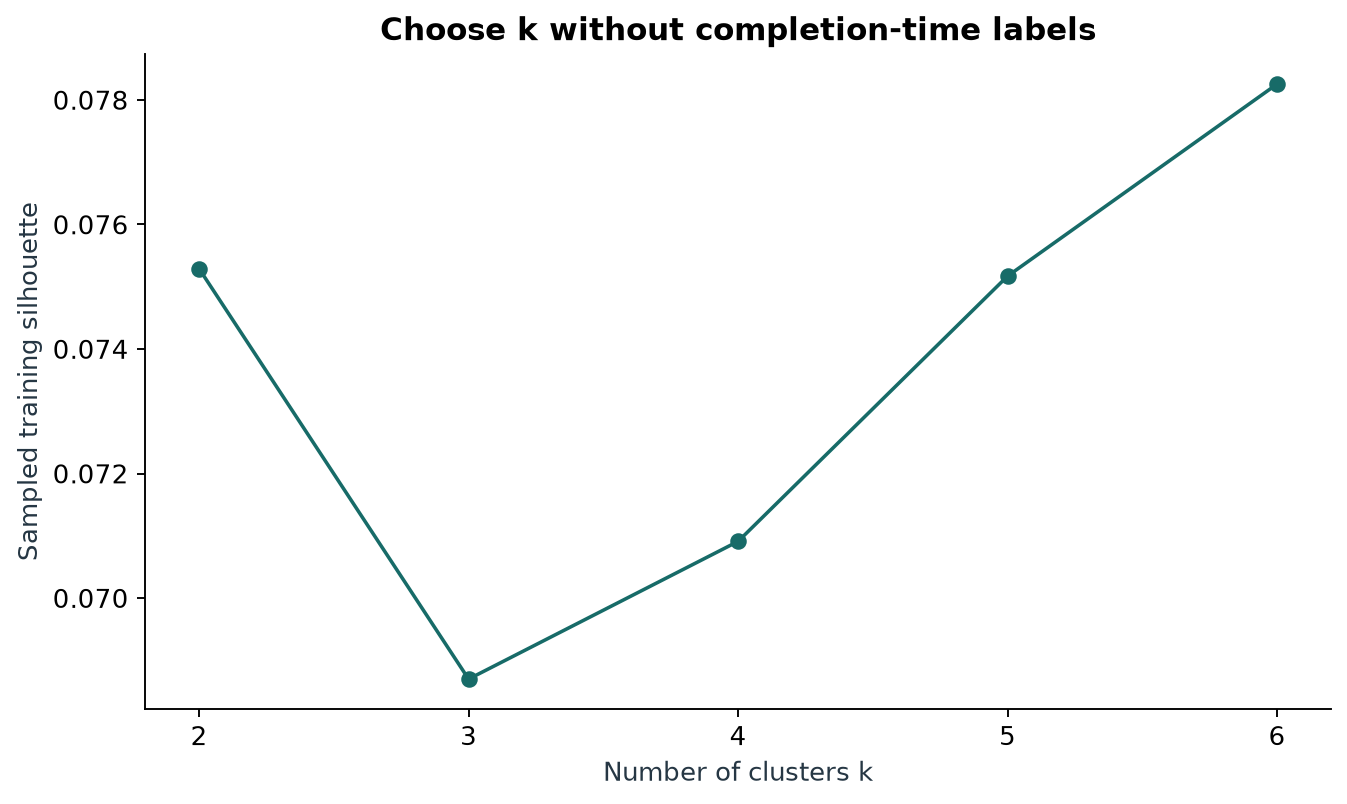

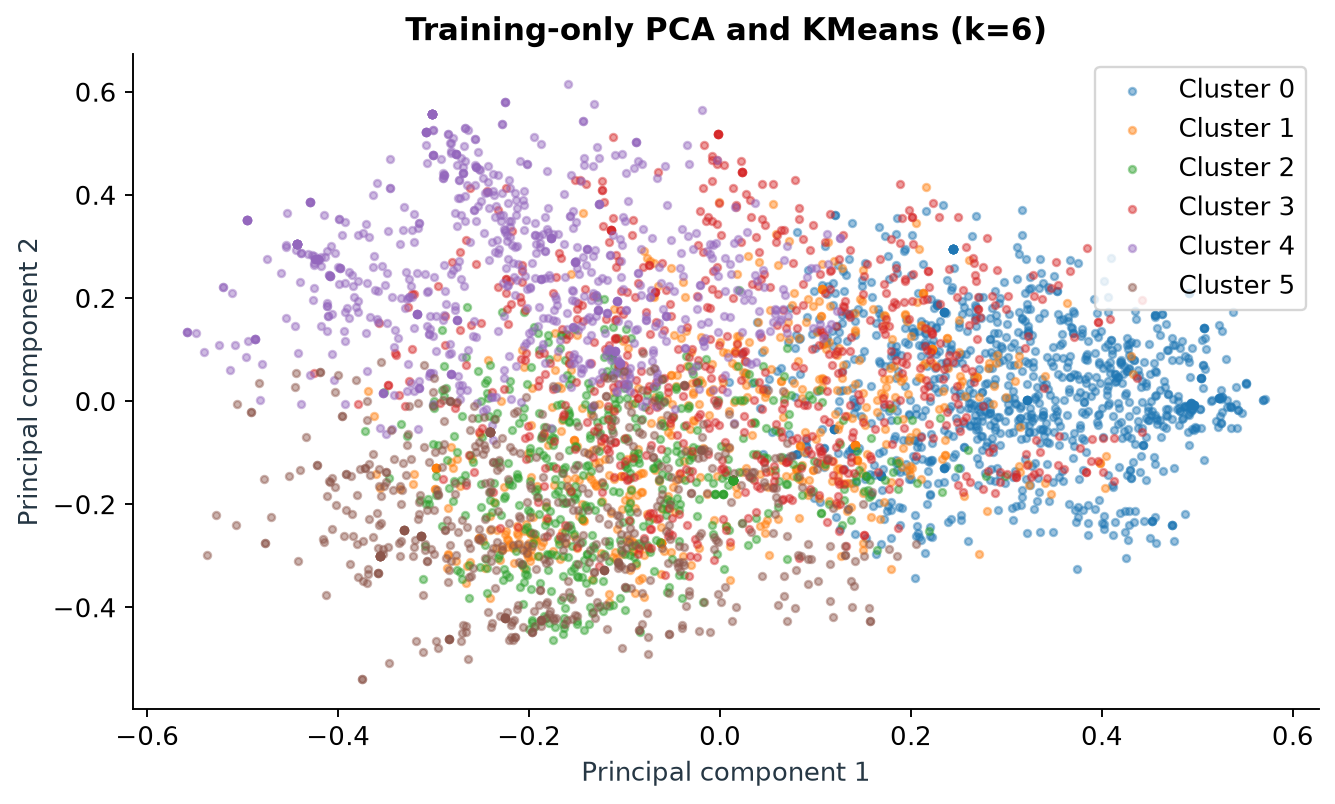

In [13]:
cluster_manifest = json.loads((OUT / 'clustering_manifest.json').read_text())
display(pd.DataFrame([{k:v for k,v in cluster_manifest.items() if k not in ['interpretation','completed_at_utc']}]).T)
display(pd.read_csv(OUT / 'cluster_selection.csv').round(4))
display(pd.read_csv(OUT / 'cluster_profiles.csv'))
for filename in ['cluster_selection.png','pca_clusters.png']:
    display(Image(filename=str(OUT / 'figures' / filename), width=760))

## 11 Conclusions and practical limits

Current metadata and the frozen October labels support retrospective catalog estimates. They do not establish launch-day forecasts or personal playtime guarantees. Steam coverage is selective, community labels have uneven reliability and the test outcomes were already observed at midterm. All extreme labels remain in the main result.


In [14]:
selected = comparison.set_index('model').loc[manifest['best_cv_model']]
median = comparison.set_index('model').loc['Median baseline']
improvement = 100 * (median.test_MAE_hours - selected.test_MAE_hours) / median.test_MAE_hours
display(Markdown(f"The selected expanded model is **{manifest['best_cv_model']}**, with test "
    f"**MAE {selected.test_MAE_hours:.2f} h**, **RMSE {selected.test_RMSE_hours:.2f} h**, "
    f"**R² {selected.test_R2:.3f}**, and median absolute error **{selected.test_MedAE_hours:.2f} h**. "
    f"Its MAE is **{improvement:.1f}% lower** than the median baseline on the same test games."))
print('Raw source values and all reported experiment outputs are included in the submission.')

The selected expanded model is **Tuned gradient boosting**, with test **MAE 10.26 h**, **RMSE 50.52 h**, **R² 0.023**, and median absolute error **2.39 h**. Its MAE is **21.2% lower** than the median baseline on the same test games.

Raw source values and all reported experiment outputs are included in the submission.


## 12 Team responsibilities and tools

**Syrym Shadiyarbek:** assigned collection, preparation, exploration and PCA/clustering.

**Yerdaulet Akhanov:** assigned modelling, tuning, neural network and evaluation.

**Both:** review conclusions and practise questions across the whole project. Individual completed work has not been confirmed; these roles should not be presented as a record of personal authorship.

**AI tools:** OpenAI Codex helped write and run code, check the data/results, and prepare the notebook, report and slides. The students are responsible for review and explanation. See `docs/CONTRIBUTIONS.md` for assigned tasks and the factual disclosure.

**Final plan:** description features, comparison with structured inputs, a local app and stronger independent validation where feasible.
